In [1]:
# I used Claude to help solidify my understanding of the grid transformation and the map it entailed
# I used Claude to help plot the visualisations in this notebook

# Cube-to-cylinder coordinate map

## Purpose

This notebook shows how the solver maps a reference cube to a cylindrical limb and evaluates the geometry required by the mapped conductivity operator. It uses the package implementations directly: max-norm square-to-disc projection, Laplacian mesh smoothing, straight extrusion, numerical Jacobian, and metric construction.

The projection-and-smoothing approach is adapted from Fanxin Sun's previous project.

In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter

from neuralphysics import SmoothingPolicy, configure, grid_at, viz
from neuralphysics.grid import (
    cartesian_to_circular,
    create_cylindrical_grid,
    smooth_grid,
)
from neuralphysics.metric import identity_metric, metric_from_jacobian
from neuralphysics.utils import to_numpy


print(configure())

{'dtype': 'torch.float64', 'seed': 42}


In [3]:
# One geometry throughout, at the resolution the experiments run at.
#
# The extent is the reference cube's, L = 1, and the spacing h = L/(N-1) is the SAME
# spacing the operator uses. That matters later: the Jacobian is a derivative with
# respect to the reference coordinates, so it has to be divided by this h and not by
# some physical spacing chosen independently of it.

N = 65                      # nodes per axis in the cross-section
NZ = 33                     # z-levels drawn for the cylinder wireframe
L = 1.0
h = L / (N - 1)

SMOOTHING = SmoothingPolicy()   # 100 iterations, del_t = 0.2 -- the package default

print(f"N = {N}, L = {L}, h = {h:.6f}, smoothing {SMOOTHING}")

N = 65, L = 1.0, h = 0.015625, smoothing SmoothingPolicy(iterations=100, del_t=0.2)


## Square-to-disc mapping

Let the centre of the haloed reference grid be

$$
o_x=\frac{h(N+1)}{2},\qquad o_y=\frac{h(N+1)}{2},
$$

and define signed offsets $u=x-o_x$ and $v=y-o_y$. Their Euclidean and max-norm radii are

$$
r=\sqrt{u^2+v^2},\qquad s=\max(|u|,|v|).
$$

The projection rescales each offset radially:

$$
x'=\frac{s}{r}u+o_x,\qquad y'=\frac{s}{r}v+o_y.
$$

The angle is unchanged and the new Euclidean radius is $s$, so each square max-norm level set becomes a circle. Points on the coordinate axes stay fixed because $s=r$; diagonal points move inward by the largest factor, $1/\sqrt{2}$. The centre is handled separately to avoid division by zero and remains fixed.

In [4]:
# The reference lattice, carrying the one-node halo the central differences need later.
i_x = np.linspace(0, (N + 1) * h, N + 2)
i_y = np.linspace(0, (N + 1) * h, N + 2)
x, y = np.meshgrid(i_x, i_y, indexing="ij")

# The projection alone: shape right, distribution wrong.
x_cir, y_cir = cartesian_to_circular(N, N, x, y, h, h)

print(f"reference lattice {x.shape}, spans [{x.min():.4f}, {x.max():.4f}]")
print(f"projected disc     {x_cir.shape}, rim at r = "
      f"{np.hypot(x_cir[0] - h * (N + 1) / 2, y_cir[0] - h * (N + 1) / 2).max():.4f}")

reference lattice (67, 67), spans [0.0000, 1.0312]
projected disc     (67, 67), rim at r = 0.5156


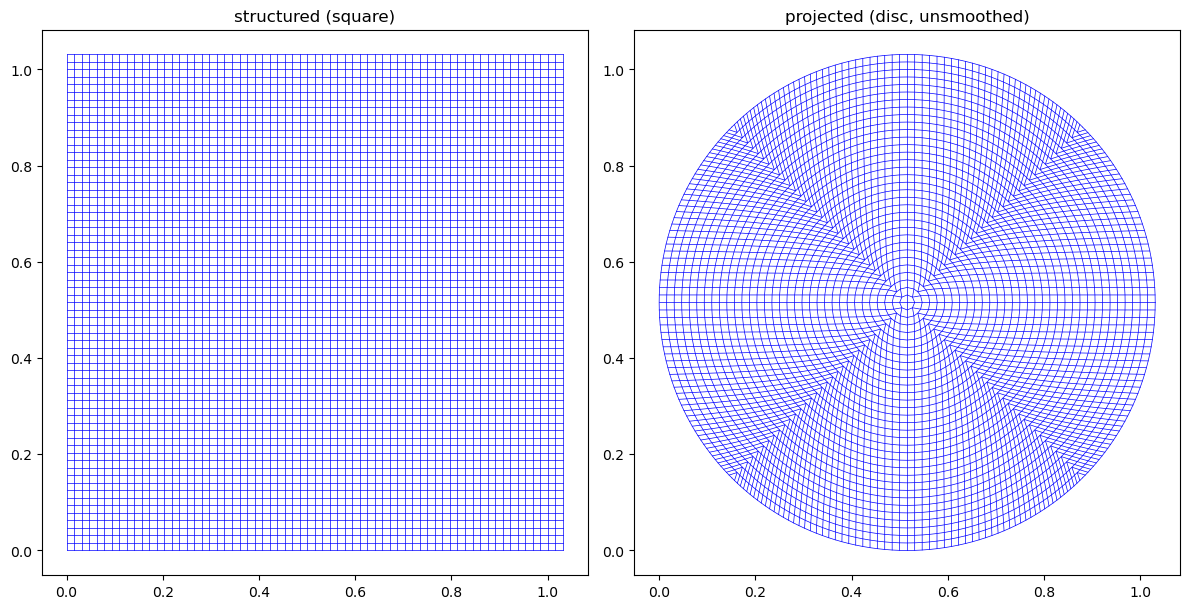

In [5]:
def plot_grid(x, y, z=None, ax=None, title=None,
              color="b", linewidth=0.5, alpha=0.2, stride=1):
    """Draw a computational grid -- 2D or 3D, structured or distorted.

    2D (square / disc): pass x, y of shape (M, N). Draws both families of grid lines.
    3D (cube / cylinder): pass x, y, z of shape (K, M, N), one wireframe per z-layer.

    'Structured' vs 'distorted' needs no special handling -- they differ only in the
    node coordinates, so the same drawing logic covers all four cases. This is the one
    helper the notebook still defines: it draws the mesh itself, which the package's
    figures (which colour fields on the mesh) do not do.
    """
    is_3d = z is not None

    if ax is None:
        if is_3d:
            fig = plt.figure(figsize=(10, 8))
            ax = fig.add_subplot(111, projection="3d")
        else:
            _, ax = plt.subplots(figsize=(6, 6))

    if is_3d:
        for k in range(0, z.shape[0], stride):
            # (x, z, y) ordering puts the cylinder axis across the page
            ax.plot_wireframe(x[k], z[k], y[k],
                              color=color, alpha=alpha, linewidth=linewidth)
        ax.view_init(elev=20, azim=45)
    else:
        ax.plot(x, y, color=color, linewidth=linewidth)       # one family of lines
        ax.plot(x.T, y.T, color=color, linewidth=linewidth)   # the other family
        ax.set_aspect("equal")

    if title is not None:
        ax.set_title(title)
    return ax


fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 6))
plot_grid(x, y, ax=ax_left, title="structured (square)")
plot_grid(y_cir, x_cir, ax=ax_right, title="projected (disc, unsmoothed)")
fig.tight_layout()

## Laplacian mesh smoothing

The radial projection creates the correct boundary but bunches nodes near the diagonal directions. The function smooth_grid improves the interior distribution by applying a Jacobi update to the $x$- and $y$-coordinate fields:

$$
u_{i,j}^{\,new}=u_{i,j}+\Delta t
\left(u_{i+1,j}+u_{i-1,j}+u_{i,j+1}+u_{i,j-1}-4u_{i,j}\right).
$$

This is a five-point Laplacian in grid-index space. Only interior nodes are updated, so the circular outer ring remains fixed. For the explicit two-dimensional update, stability requires $\Delta t\leq 1/4$; the default is $\Delta t=0.2$. After 100 iterations the cells are better distributed, but not perfectly uniform, and the smoothing does not turn the piecewise-defined raw projection into a closed-form smooth map.

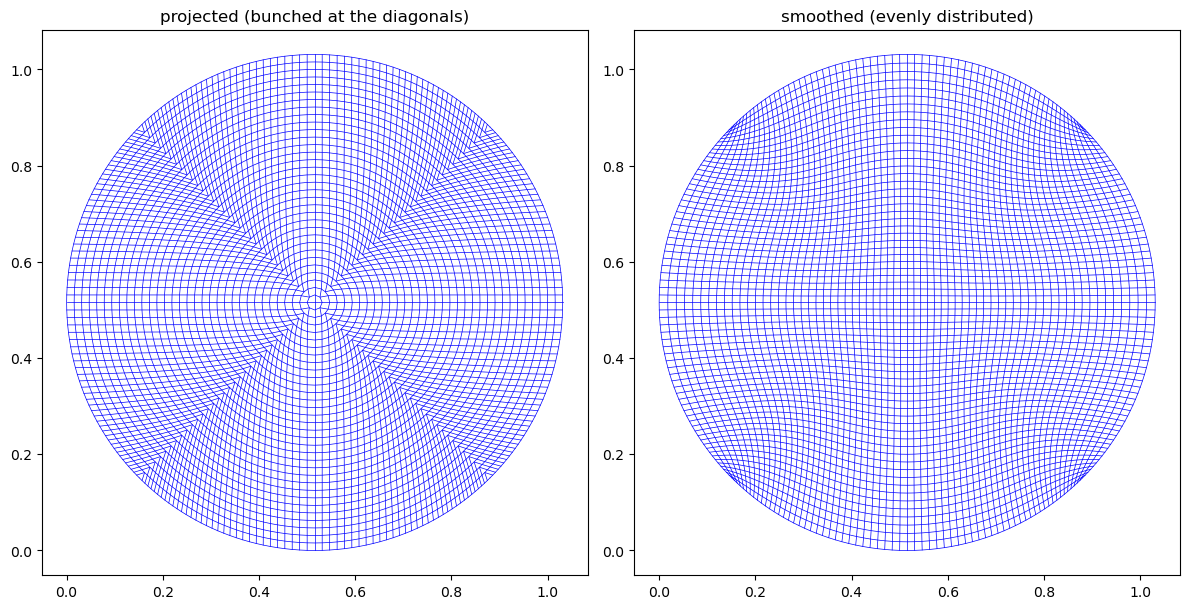

In [6]:
x_cir_sm, y_cir_sm = smooth_grid(x_cir, y_cir,
                                 iterations=SMOOTHING.iterations, del_t=SMOOTHING.del_t)

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 6))
plot_grid(y_cir, x_cir, ax=ax_left, title="projected (bunched at the diagonals)")
plot_grid(y_cir_sm, x_cir_sm, ax=ax_right, title="smoothed (evenly distributed)")
fig.tight_layout()

## Straight extrusion

The smoothed disc is replicated on uniformly spaced $z$ levels. Every cross-section is identical, so the resulting metric fields are invariant along $z$.

cylinder node arrays (35, 67, 67), z spans [0.0000, 0.5312]


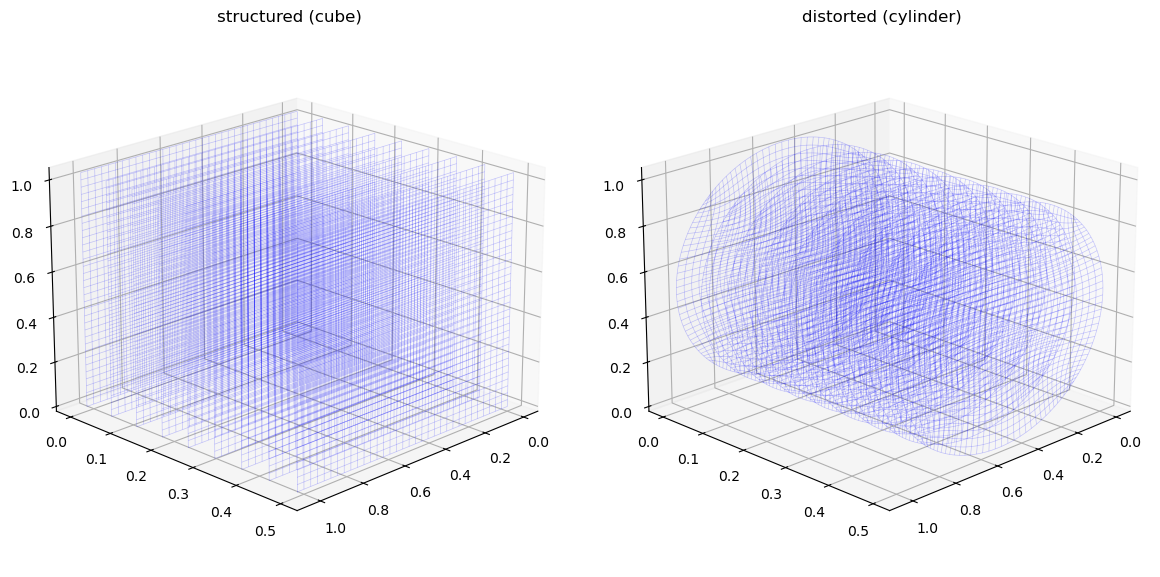

In [7]:
X_cyl, Y_cyl, Z_cyl = create_cylindrical_grid(N, N, NZ, x, y, h, h, h,
                                              smoothing=SMOOTHING)

# the undistorted cube, for the same node count, to compare against
Z_ref = np.linspace(0, (NZ + 1) * h, NZ + 2)
X_cube = np.tile(x, (NZ + 2, 1, 1))
Y_cube = np.tile(y, (NZ + 2, 1, 1))
Z_cube = np.tile(Z_ref[:, None, None], (1, N + 2, N + 2))

print(f"cylinder node arrays {X_cyl.shape}, z spans "
      f"[{Z_cyl.min():.4f}, {Z_cyl.max():.4f}]")

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 6),
                                        subplot_kw={"projection": "3d"})
plot_grid(X_cube, Y_cube, Z_cube, ax=ax_left, title="structured (cube)", stride=4)
plot_grid(X_cyl, Y_cyl, Z_cyl, ax=ax_right, title="distorted (cylinder)", stride=4)
fig.tight_layout()
fig.subplots_adjust(top=0.92)   # 3D axes crowd the titles out otherwise

## Jacobian of the coordinate map

The projection followed by smoothing defines the sampled map

$$
\Phi:(\xi,\eta)\mapsto\bigl(x(\xi,\eta),y(\xi,\eta)\bigr).
$$

Its in-plane Jacobian is

$$
J=\frac{\partial(x,y)}{\partial(\xi,\eta)}
=
\begin{bmatrix}
x_\xi & x_\eta\\
y_\xi & y_\eta
\end{bmatrix}.
$$

The smoothed map is represented only by node coordinates, so jacobian_num estimates these derivatives with centred differences using the reference spacing $h=L/(N-1)$. The coordinate arrays include a one-node halo, allowing centred differences at every solved node. The returned Jacobian also has a replicated outer shell for compatibility, but metric_from_jacobian crops that shell before constructing the operator coefficients.

The determinant gives the sampled local area scale, while $J^{-1}$ and $\det J$ carry derivatives from the physical cylinder to the reference cube. Using the reference spacing is essential: the identity map should return $J=I$.

In [8]:
# CylinderGrid runs the same projection, smoothing and extrusion as above and measures
# the Jacobian off the node positions it produced -- so this grid IS the geometry the
# forward solve uses, not a re-derivation of it.
grid = grid_at(N, L=L, smoothing=SMOOTHING)

J = grid.jacobian
rim = grid.rim_stats("physical")

print(grid)
print(f"J           shape {tuple(J.shape)}  (2, 2, N+2, N+2), halo included")
print(f"nodes agree with the hand-built disc: "
      f"{np.allclose(grid.coords_haloed[0], x_cir_sm) and np.allclose(grid.coords_haloed[1], y_cir_sm)}")
print(f"det(J)      min {float(grid.det_J.min()):.5f}, max {float(grid.det_J.max()):.5f}, "
      f"mean {float(grid.det_J.mean()):.5f}")
print(f"rim radius  mean {rim['mean']:.5f}, spread {rim['spread']:.2e} "
      f"({rim['spread_in_h']:.3f} h)")

CylinderGrid(n=65, L=1.0, smoothing=SmoothingPolicy(iterations=100, del_t=0.2), z_zeta=1.0, mapped=True)
J           shape (2, 2, 67, 67)  (2, 2, N+2, N+2), halo included
nodes agree with the hand-built disc: True
det(J)      min 0.11417, max 1.11886, mean 0.78625
rim radius  mean 0.50144, spread 1.62e-02 (1.035 h)


In [9]:
# need to fix the duplicate explanation

## Metric coefficients

For

$$
J=\begin{pmatrix}a&b\\c&d\end{pmatrix},
\qquad \det J=ad-bc,
$$

the mapped operator uses

$$
m_{xx}=\frac{z_\zeta(b^2+d^2)}{\det J},\qquad
m_{yy}=\frac{z_\zeta(a^2+c^2)}{\det J},
$$

$$
m_{xy}=-\frac{z_\zeta(ab+cd)}{\det J},\qquad
m_L=\frac{\det J}{z_\zeta}.
$$

The off-diagonal coefficient $m_{xy}$ retains the shear introduced by the map; all four fields reduce to the identity-metric values $(1,0,1,1)$ on an undistorted grid.

The next plots show the four signed Jacobian derivatives and the four metric fields constructed from them.

A positive determinant at every sampled node is the mesh-validity check used by CylinderGrid. It shows that the sampled local orientation is preserved, although it does not prove that no folding occurs between nodes. A zero or negative sampled determinant would make the metric invalid.

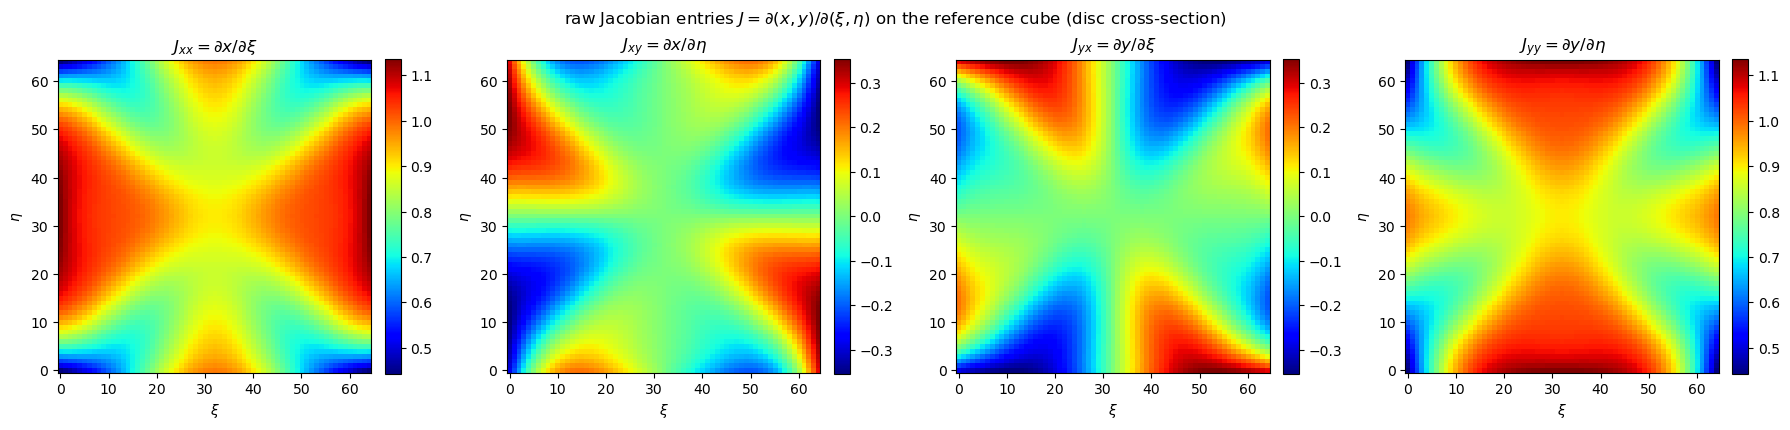

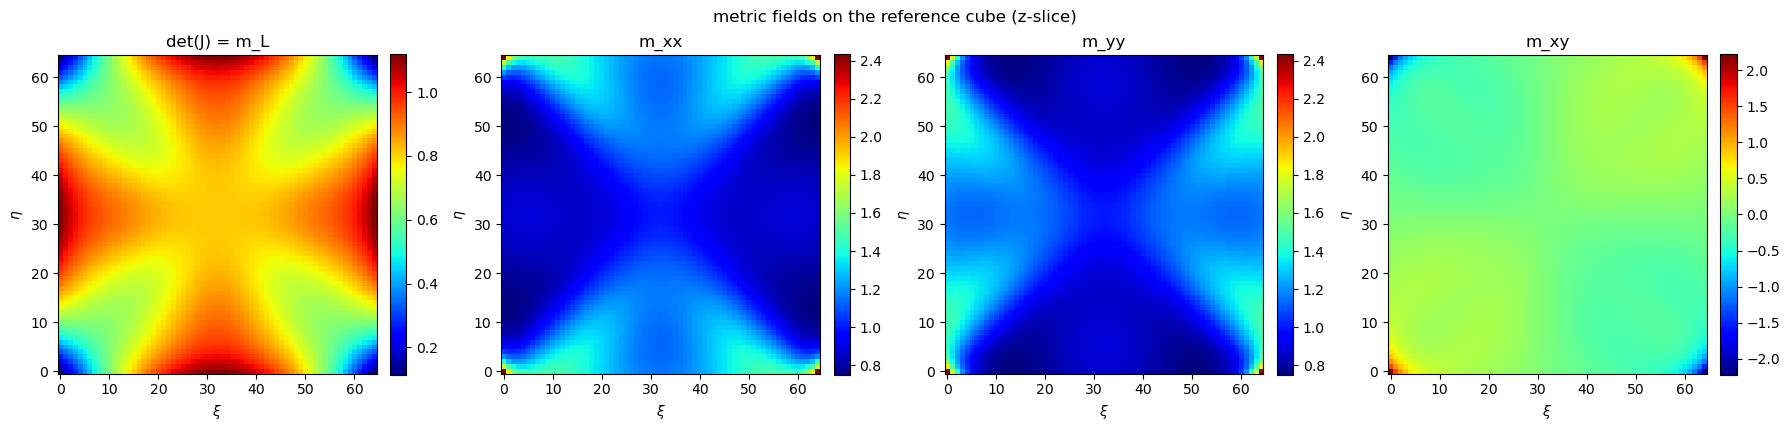

In [10]:
fig_jacobian = viz.plot_jacobian_fields(grid)
fig_metric = viz.plot_metric_fields(grid)

In [11]:
# The identity-map oracle: bypass the projection entirely and the same machinery must
# return J = I exactly, hence M_T = (1, 0, 1) and m_L = 1 -- the Cartesian operator.
# This is what pins the denominator convention: dividing by anything other than the
# reference spacing h would rescale J and this check would fail.
flat = grid_at(N, L=L, mapped=False)
J_flat = flat.jacobian[:, :, 1:-1, 1:-1]
eye = torch.eye(2, dtype=J_flat.dtype)[:, :, None, None].expand_as(J_flat)

print(f"undistorted grid: J = I to {float((J_flat - eye).abs().max()):.2e}")
print(f"                  metric = identity: "
      f"{all(torch.allclose(a, b) for a, b in zip(flat.metric, identity_metric(N)))}")

# and the mapped metric is z-invariant, because the extrusion is straight
mxx, mxy, myy, mL = grid.metric
print(f"mapped grid:      metric fields {tuple(mxx.shape)}, "
      f"z-invariant to {float((mxx - mxx[:, :, :1]).abs().max()):.2e}")
print(f"                  det(J) rebuilt from J matches grid.det_J: "
      f"{torch.allclose(metric_from_jacobian(grid.jacobian, N, grid.z_zeta)[3], mL)}")

undistorted grid: J = I to 0.00e+00
                  metric = identity: True
mapped grid:      metric fields (65, 65, 65), z-invariant to 0.00e+00
                  det(J) rebuilt from J matches grid.det_J: True


## Interpreting the fields

- The determinant remains positive at the sampled nodes; its variation shows the area non-uniformity left after smoothing.
- Nonzero $m_{xy}$ records the coupling introduced by the mapped grid and vanishes for the identity map.
- The plotted Jacobian's outer shell is replicated rather than differentiated. The production metric crops this shell and uses the derivatives evaluated at the solved nodes.

## Diagonal seam

The raw max-norm projection is continuous but changes derivative across the four diagonals, where the coordinate attaining the maximum switches. Smoothing reduces this sampled kink without giving the composite map a closed-form derivative. The following cells measure this geometric defect and its refinement behaviour.

In [12]:
def raw_map(p, q):
    """The projection step alone, applied to offsets from the disc centre.

    (rho, theta) -> (rho * max(|cos|, |sin|), theta). This is `cartesian_to_circular`
    written closed-form, so it can be sampled off the node lattice and the kink shown
    as a property of the map rather than of any particular grid.
    """
    rho = np.hypot(p, q)
    s = np.divide(np.maximum(np.abs(p), np.abs(q)), rho,
                  out=np.ones_like(rho), where=rho > 0)
    return s * p, s * q


def index_polar(n):
    """(L-inf index radius, perpendicular index distance to the nearest diagonal).

    Both in cells, in the operator's [xi, eta] layout. Index units rather than
    physical ones because the smoothing acts a fixed number of index steps, so the
    seam band is a fixed number of cells wide at every resolution.
    """
    i, j = np.meshgrid(np.arange(n), np.arange(n), indexing="ij")
    c = (n - 1) / 2.0
    p, q = i - c, j - c
    return np.maximum(np.abs(p), np.abs(q)), np.abs(np.abs(p) - np.abs(q)) / np.sqrt(2)


def seam_curvature(g):
    """max |second difference| / h^2 over {x, y} x {xi, eta}, on the interior nodes.

    A second difference of a C^2 map is h^2 times a bounded second derivative, so
    this is O(1) under refinement. Across a kink it is h times the jump in the first
    derivative, so it grows like 1/h. That contrast is the whole diagnostic.
    """
    Xh, Yh = g.coords_haloed
    out = []
    for A in (Xh.T, Yh.T):                     # [eta, xi] -> [xi, eta]
        out.append(np.abs(A[2:, 1:-1] - 2 * A[1:-1, 1:-1] + A[:-2, 1:-1]) / g.h ** 2)
        out.append(np.abs(A[1:-1, 2:] - 2 * A[1:-1, 1:-1] + A[1:-1, :-2]) / g.h ** 2)
    return np.maximum.reduce(out)

In [13]:
a, s = 1.0, 1.0 / (2 * np.sqrt(2))
JA = s * np.array([[3.0, -1.0], [1.0, 1.0]])       # |p| > |q|
JB = s * np.array([[1.0,  1.0], [-1.0, 3.0]])      # |q| > |p|

def one_sided(p, q, eps):
    f0 = np.array(raw_map(np.array(p), np.array(q)))
    fp = np.array(raw_map(np.array(p + eps), np.array(q)))
    fq = np.array(raw_map(np.array(p), np.array(q + eps)))
    return np.stack([(fp - f0) / eps, (fq - f0) / eps], axis=1)

print("max |closed form - one-sided FD|:",
      max(np.abs(JA - one_sided(a, a - 1e-5, -1e-9)).max(),
          np.abs(JB - one_sided(a - 1e-5, a, -1e-9)).max()))

def metric_of(J):
    (a_, b_), (c_, d_) = J
    det = a_ * d_ - b_ * c_
    return (b_ * b_ + d_ * d_) / det, -(a_ * b_ + c_ * d_) / det, \
           (a_ * a_ + c_ * c_) / det, det

print(f"||J_B - J_A||_F = {np.linalg.norm(JB - JA):.6f}   (sqrt 2 = {np.sqrt(2):.6f})")
for tag, J in (("|p|>|q|", JA), ("|q|>|p|", JB)):
    mxx, mxy, myy, det = metric_of(J)
    print(f"{tag}:  m_xixi {mxx:.4f}   m_xieta {mxy:.4f}   "
          f"m_etaeta {myy:.4f}   det J {det:.4f}")

max |closed form - one-sided FD|: 5.347248989595599e-06
||J_B - J_A||_F = 1.414214   (sqrt 2 = 1.414214)
|p|>|q|:  m_xixi 0.5000   m_xieta 0.5000   m_etaeta 2.5000   det J 0.5000
|q|>|p|:  m_xixi 2.5000   m_xieta 0.5000   m_etaeta 0.5000   det J 0.5000



A. identity map (mapped=False): expect second order, no contrast
      n  seam max|tau|   off max|tau|    ratio  rate seam  rate off   band sizes
     33     9.4706e-03     1.5545e-02     0.61                           36 /    324
     65     2.1759e-03     3.9204e-03     0.56       2.12      1.99      76 /   2204
    129     5.1975e-04     9.8015e-04     0.53       2.07      2.00     152 /  10336
    257     1.2690e-04     2.4504e-04     0.52       2.03      2.00     308 /  44660

B. SMOOTH_MAP, numerically measured det J: expect second order
      n  seam max|tau|   off max|tau|    ratio  rate seam  rate off   band sizes
     33     1.5722e-02     2.7837e-02     0.56                           36 /    324
     65     4.1763e-03     7.1206e-03     0.59       1.91      1.97      76 /   2204
    129     1.1334e-03     1.7831e-03     0.64       1.88      2.00     152 /  10336
    257     2.9404e-04     4.4610e-04     0.66       1.95      2.00     308 /  44660

control A passed: True    c

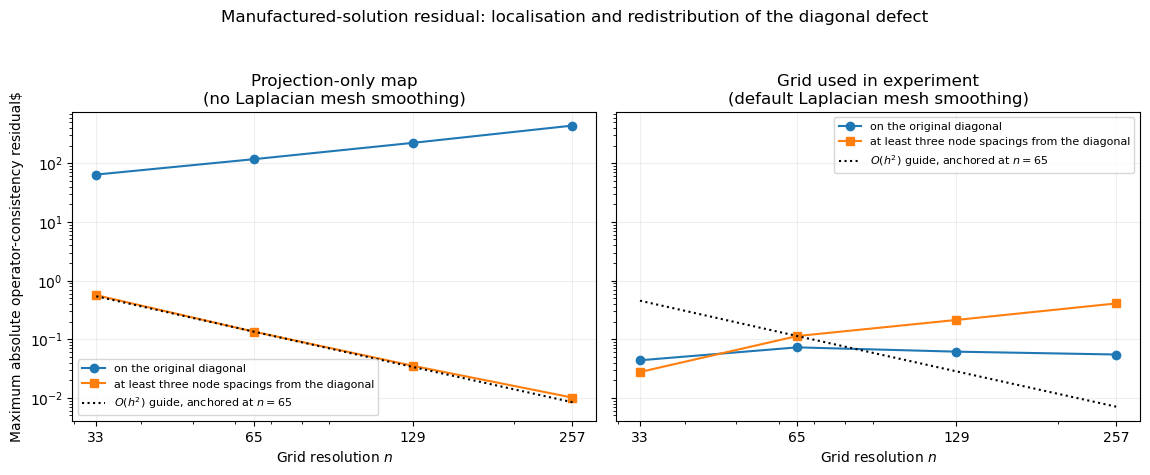

In [18]:
# ---------------------------------------------------------------------------
# The ACCURACY cost of the seam, as opposed to its geometric defect.
#
# Panel (d) measures the map's discrete curvature: a property of the geometry.
# This measures what that geometry costs the DISCRETISATION -- the local
# manufactured-solution residual of the operator the solver actually applies --
# using the method in src/neuralphysics/verification/convergence.py, posed on the square-to-disc
# grids instead of on SMOOTH_MAP:
#
#     tau = laplacian_metric_3D(phi_mms) - det_J * L_phys(phi_mms)
#
# phi_mms and L_phys are imported unchanged. The geometry -- node positions,
# metric and det J -- is the grid's own, so phi is sampled exactly where the
# metric was measured (node i at reference (i+1)h). convergence.py records that
# rebuilding either from a separate linspace desynchronises the two and silently
# drops the observed order from two to one, which is indistinguishable from the
# effect being measured here.
#
# THE det_J CONVENTION. The production map has no closed form, so there is no
# analytic det J for the right-hand side and the grid's numerically measured one
# is used. tau is therefore the operator's consistency error against the PDE AS
# THE DISCRETE METRIC REPRESENTS IT, not against the exact continuum map. Two
# consequences, both handled rather than hidden: the absolute level of tau is
# convention-dependent, so the CONTRAST between two bands carrying the same
# convention is the defensible quantity; and the convention could in principle
# flatter the operator by cancelling part of the metric error, which is what
# controls A and B below exist to rule out.
from neuralphysics.metric import jacobian_num
from neuralphysics.operators import face_coefficients, laplacian_metric_3D
from neuralphysics.verification import SMOOTH_MAP, L_phys, phi_mms

SIGMA_T, SIGMA_L = 1.0, 5.0   # homogeneous and distinct, as in tests/test_mms.py:
                              # a smooth sigma has no transmission condition, so the
                              # only error source left is the stencil on this geometry
STRIP = 3                     # layers dropped at every face, per convergence.py
NS_TAU = (33, 65, 129, 257)   # refinements used in both comparison panels


def mms_tau(coords, metric, det_J, h, sigma_T=SIGMA_T, sigma_L=SIGMA_L):
    """Return the (n, n, n) manufactured residual of laplacian_metric_3D.

    `coords` are the physical node positions in the operator's [xi, eta] layout,
    `metric` the four fields built from the same nodes, `det_J` the volume ratio
    used on the right-hand side. Nothing is resampled: whatever geometry is passed
    in is the geometry phi is evaluated on.
    """
    X, Y = coords
    n = X.shape[0]
    X3 = np.repeat(X[:, :, None], n, axis=2)
    Y3 = np.repeat(Y[:, :, None], n, axis=2)
    Z3 = np.broadcast_to(np.arange(n) * h, (n, n, n))   # convergence.py's z: k*h
    sTf = torch.full((n, n, n), float(sigma_T))
    sLf = torch.full((n, n, n), float(sigma_L))
    faces = face_coefficients(metric, sTf, sLf)
    num = laplacian_metric_3D(torch.as_tensor(phi_mms(X3, Y3, Z3)), h, faces, metric, sTf)
    return to_numpy(num) - to_numpy(det_J) * L_phys(X3, Y3, Z3, sigma_T, sigma_L)


def geometry_of(g):
    """The four arguments mms_tau needs, read off a CylinderGrid."""
    return g.coords, g.metric, g.det_J, g.h


def smooth_map_numeric(n):
    """SMOOTH_MAP with det J MEASURED rather than taken from SmoothAnalyticMap.det_J.

    Same sampling as convergence.py, so the only difference from `mms_error` is the
    det J convention -- which is what control B is testing.
    """
    h = 1.0 / (n - 1)
    r = np.arange(n + 2) * h                          # haloed reference nodes
    ETA_g, XI_g = np.meshgrid(r, r, indexing="ij")    # [row = eta, col = xi]
    J2 = jacobian_num(torch.as_tensor(SMOOTH_MAP.x(XI_g, ETA_g)),
                      torch.as_tensor(SMOOTH_MAP.y(XI_g, ETA_g)), n, n)
    metric = metric_from_jacobian(J2, n, z_zeta=1.0)
    ax_ = (np.arange(n) + 1) * h                      # operator node i -> (i+1)h
    Xi, Eta = np.meshgrid(ax_, ax_, indexing="ij")
    return (SMOOTH_MAP.x(Xi, Eta), SMOOTH_MAP.y(Xi, Eta)), metric, metric[3], h


def tau_bands(n):
    """Return masks on and outside a narrow band around the original diagonals.

    The first mask selects the diagonal nodes. The second begins three grid cells
    from the diagonals: for the projection-only map this excludes stencils crossing
    the kink, while after mesh smoothing it can contain residual redistributed away
    from the original diagonal. Keeping the same masks is therefore intentional.

    The bands are defined in index space and hence shrink in coordinate-space width
    under refinement. The annulus excludes the disc centre, where the max-norm map
    has a separate singularity, and the outer boundary region.
    """
    l2, d2 = index_polar(n)
    half = (n - 1) / 2.0
    ann = (l2 > 0.30 * half) & (l2 < 0.90 * half)
    return ann & (d2 <= 0.5), ann & (d2 >= 3.0)


def band_max(tau, mask, m=STRIP):
    """(max |tau| over the band, node count). The 2D mask broadcasts along z; the
    strip is dropped on all six faces first, because the reflect padding makes the
    outer rows impose the Neumann condition and the cross term pads twice."""
    core, mk = tau[m:-m, m:-m, m:-m], mask[m:-m, m:-m]
    return (float(np.abs(core[mk]).max()), int(mk.sum())) if mk.any() else (np.nan, 0)


def tau_series(build, Ns=NS_TAU):
    """max |tau| on each band at each n, plus the log2 rates between consecutive n."""
    seam, off, counts = [], [], []
    for nn in Ns:
        tau = mms_tau(*build(nn))
        ms, mo = tau_bands(nn)
        (sv, sc), (ov, oc) = band_max(tau, ms), band_max(tau, mo)
        seam.append(sv); off.append(ov); counts.append((sc, oc))
    rate = lambda v: [np.log2(v[k] / v[k + 1]) for k in range(len(v) - 1)]
    return {"Ns": list(Ns), "seam": seam, "off": off, "counts": counts,
            "rate_seam": rate(seam), "rate_off": rate(off)}


def show_series(tag, s):
    print(f"\n{tag}")
    print(f"  {'n':>5} {'seam max|tau|':>14} {'off max|tau|':>14} {'ratio':>8} "
          f"{'rate seam':>10} {'rate off':>9}   band sizes")
    for k, nn in enumerate(s["Ns"]):
        rs = "" if k == 0 else f"{s['rate_seam'][k-1]:10.2f}"
        ro = "" if k == 0 else f"{s['rate_off'][k-1]:9.2f}"
        print(f"  {nn:5d} {s['seam'][k]:14.4e} {s['off'][k]:14.4e} "
              f"{s['seam'][k]/s['off'][k]:8.2f} {rs:>10} {ro:>9}   "
              f"{s['counts'][k][0]:5d} / {s['counts'][k][1]:6d}")


# ---- controls: printed, not plotted ---------------------------------------
# Both are cheap, and both are what stop the figure being an artefact of the
# harness rather than a measurement of the geometry.

# A. Identity map: J = I, det J = 1. Second order in both bands, and no band
#    contrast, proves the band masks and the boundary strip do not manufacture a
#    contrast by themselves. It exercises the diagonal flux terms only -- the
#    operator skips the cross term when mxy is identically zero -- which is why
#    control B, on a sheared map, is also needed.
ctrl_identity = tau_series(lambda nn: geometry_of(grid_at(nn, mapped=False)))
show_series("A. identity map (mapped=False): expect second order, no contrast", ctrl_identity)

# B. SMOOTH_MAP with det J measured numerically instead of analytically. Second
#    order surviving proves the det_J convention used above is not itself a source
#    of order loss.
ctrl_smooth = tau_series(smooth_map_numeric)
show_series("B. SMOOTH_MAP, numerically measured det J: expect second order", ctrl_smooth)

A_OK = (min(ctrl_identity["rate_seam"][-1], ctrl_identity["rate_off"][-1]) > 1.8
        and max(r := [s / o for s, o in zip(ctrl_identity["seam"], ctrl_identity["off"])])
            / min(r) < 2.0)
B_OK = min(ctrl_smooth["rate_seam"][-1], ctrl_smooth["rate_off"][-1]) > 1.8
print(f"\ncontrol A passed: {A_OK}    control B passed: {B_OK}")
if not (A_OK and B_OK):
    raise RuntimeError("a control failed -- the production numbers below would not "
                       "be attributable to the geometry, so nothing is plotted")

# ---- the two mapped-grid measurements -------------------------------------
# `prod` applies the default Laplacian mesh-smoothing policy. `raw` turns that
# smoothing off. Both use the same manufactured solution, operator and masks, so
# their panels compare localisation before smoothing with redistribution after it.
prod = tau_series(lambda nn: geometry_of(grid_at(nn)))
show_series("production grid (default SmoothingPolicy): the measurement", prod)

# C. Projection-only reference. Comparing this with `prod` distinguishes removal
#    of the large pointwise spike from redistribution into neighbouring grid layers.
raw = tau_series(lambda nn: geometry_of(grid_at(nn, smoothing=SmoothingPolicy(iterations=0))))
show_series("C. projection only (iterations=0), for reference", raw)

print(f"\nsmoothing cuts the worst interior |tau| at n = {NS_TAU[-1]} by a factor of "
      f"{max(raw['seam'][-1], raw['off'][-1]) / max(prod['seam'][-1], prod['off'][-1]):.0f}, "
      f"but neither band converges on the production grid:\n  seam rates "
      f"{[round(v, 2) for v in prod['rate_seam']]}, outside-band rates "
      f"{[round(v, 2) for v in prod['rate_off']]} (second order would be +2).")


# ---- side-by-side comparison ----------------------------------------------
# Each panel receives its own vertically anchored O(h^2) guide. The guides show
# the expected slope only; matching them at n=65 does not assert that either
# measured series is second order.
ANCHOR_N = 65


def plot_tau_panel(ax, data, title):
    """Plot the same diagonal-band diagnostic for one grid construction."""
    anchor = data["Ns"].index(ANCHOR_N)
    ref = [
        data["off"][anchor] * ((ANCHOR_N - 1) / (nn - 1))**2
        for nn in data["Ns"]
    ]

    ax.loglog(data["Ns"], data["seam"], "o-",
              label="on the original diagonal")
    ax.loglog(data["Ns"], data["off"], "s-",
              label="at least three node spacings from the diagonal")
    ax.loglog(data["Ns"], ref, "k:",
              label=rf"$O(h^2)$ guide, anchored at $n={ANCHOR_N}$")

    ax.set_xticks(data["Ns"])
    ax.set_xticklabels(map(str, data["Ns"]))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel(r"Grid resolution $n$")
    ax.set_title(title)
    ax.grid(True, which="major", alpha=0.20)
    ax.legend(fontsize=8)


fig_tau, ax_tau = plt.subplots(
    1, 2, figsize=(11.6, 4.8), sharex=True, sharey=True
)

plot_tau_panel(
    ax_tau[0], raw,
    "Projection-only map\n(no Laplacian mesh smoothing)"
)
plot_tau_panel(
    ax_tau[1], prod,
    "Grid used in experiment\n(default Laplacian mesh smoothing)"
)

ax_tau[0].set_ylabel(r"Maximum absolute operator-consistency residual$")
fig_tau.suptitle(
    "Manufactured-solution residual: localisation and redistribution "
    "of the diagonal defect"
)
fig_tau.tight_layout(rect=(0, 0, 1, 0.94))

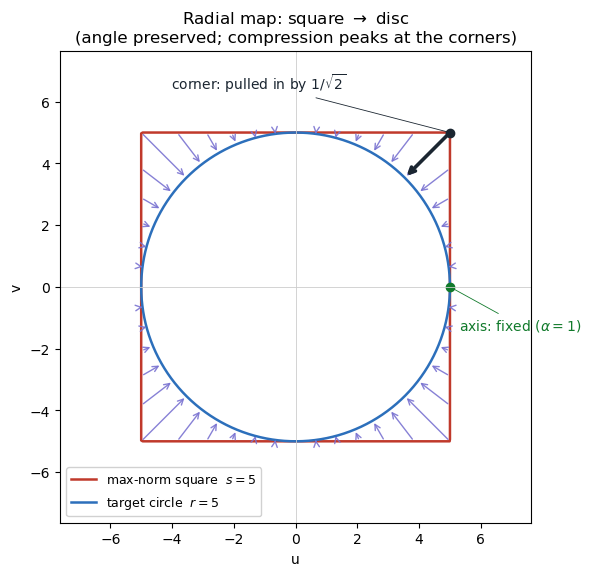

In [17]:
# --- the raw max-norm square-to-disc map (cartesian_to_circular, pre-smoothing) ---
# A point on the square of max-norm radius s, at polar angle theta, sits at Euclidean
# radius r = s/alpha(theta) with alpha(theta) = max(|cos|,|sin|); the map pulls it
# radially inward to Euclidean radius s (same angle). alpha = 1 on the axes (no move),
# alpha = 1/sqrt(2) on the diagonals (maximum inward pull) -> corner compression.
s = 5.0
alpha = lambda t: np.maximum(np.abs(np.cos(t)), np.abs(np.sin(t)))
P = lambda t: (s / alpha(t))[..., None] * np.stack([np.cos(t), np.sin(t)], -1)  # square pre-image
Q = lambda t: s * np.stack([np.cos(t), np.sin(t)], -1)                           # circle image

th = np.linspace(0, 2 * np.pi, 48, endpoint=False)
Pp, Qq = P(th), Q(th)

fig, ax = plt.subplots(figsize=(6, 6))

# square boundary and target circle (smooth outlines)
tt = np.linspace(0, 2 * np.pi, 800)
ax.plot(*P(tt).T, color="#C0392B", lw=1.8, label=r"max-norm square  $s=5$")
ax.plot(*Q(tt).T, color="#2C6FBB", lw=1.8, label=r"target circle  $r=5$")

# radial arrows: every square point pulled inward to its image on the circle
for p, q in zip(Pp, Qq):
    ax.annotate("", xy=q, xytext=p,
                arrowprops=dict(arrowstyle="->", color="#7A73D1", lw=1.0, alpha=0.9))

# highlight the maximal (diagonal) spoke and the fixed (axis) point
pc, qc = P(np.array([np.pi / 4]))[0], Q(np.array([np.pi / 4]))[0]
ax.annotate("", xy=qc, xytext=pc,
            arrowprops=dict(arrowstyle="->", color="#1B2631", lw=2.6))
ax.plot(*pc, "o", color="#1B2631", ms=6)
ax.plot(s, 0, "o", color="#117A2B", ms=6)

ax.annotate(r"corner: pulled in by $1/\sqrt{2}$", xy=pc, xytext=(-1.2, 6.4),
            fontsize=10, color="#1B2631", ha="center",
            arrowprops=dict(arrowstyle="-", color="#1B2631", lw=0.6))
ax.annotate(r"axis: fixed ($\alpha=1$)", xy=(s, 0), xytext=(s + 0.3, -1.4),
            fontsize=10, color="#117A2B", ha="left",
            arrowprops=dict(arrowstyle="-", color="#117A2B", lw=0.6))

ax.set_aspect("equal")
lim = s * np.sqrt(2) * 1.08
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.axhline(0, color="0.8", lw=0.6); ax.axvline(0, color="0.8", lw=0.6)
ax.set_xlabel("u"); ax.set_ylabel("v")
ax.set_title("Radial map: square $\\to$ disc\n(angle preserved; compression peaks at the corners)")
ax.legend(loc="lower left", fontsize=9, framealpha=0.9)
fig.tight_layout()
plt.show();